# BMW Sales Data (2010-2024): Does the Data Support Business Conclusions?

Before building dashboards or models on a dataset, it should be checked for quality and for real signal.
This notebook audits a 50,000-row BMW sales dataset and tests, with statistics and machine learning,
whether vehicle attributes (model, region, fuel, price, mileage, ...) explain sales volume
or the High/Low sales classification.

**Plan**
1. Load and inspect the data
2. Data quality checks (classification rule, distributions, implausible combinations)
3. Do attributes explain sales? (correlation, Kruskal-Wallis, chi-square)
4. Can a model predict High vs Low sales? (and a target-leakage demonstration)
5. Conclusion

## 1. Load and inspect

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

path = glob.glob("*BMW*.csv")[0]
df = pd.read_csv(path)
print("File:", path)
print("Shape:", df.shape)
print()
print(df.dtypes)
print()
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.head()

File: BMW sales data (2010-2024).csv
Shape: (50000, 11)

Model                    object
Year                      int64
Region                   object
Color                    object
Fuel_Type                object
Transmission             object
Engine_Size_L           float64
Mileage_KM                int64
Price_USD                 int64
Sales_Volume              int64
Sales_Classification     object
dtype: object

Missing values: 0
Duplicate rows: 0


,Model,Year,Region,Color,Fuel_Type,Transmission,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume,Sales_Classification
0,5 Series,2016,Asia,Red,Petrol,Manual,3.5,151748,98740,8300,High
1,i8,2013,North America,Red,Hybrid,Automatic,1.6,121671,79219,3428,Low
2,5 Series,2022,North America,Blue,Petrol,Automatic,4.5,10991,113265,6994,Low
3,X3,2024,Middle East,Blue,Petrol,Automatic,1.7,27255,60971,4047,Low
4,7 Series,2020,South America,Black,Diesel,Manual,2.1,122131,49898,3080,Low


In [2]:
cat_cols = ["Model", "Region", "Color", "Fuel_Type", "Transmission"]
num_cols = ["Year", "Engine_Size_L", "Mileage_KM", "Price_USD", "Sales_Volume"]

print(df[num_cols].describe().round(1).T)
print()
for c in cat_cols + ["Sales_Classification"]:
    print(c, "->", df[c].nunique(), "values:", sorted(df[c].unique()))

                 count      mean      std      min      25%       50%  \
Year           50000.0    2017.0      4.3   2010.0   2013.0    2017.0   
Engine_Size_L  50000.0       3.2      1.0      1.5      2.4       3.2   
Mileage_KM     50000.0  100307.2  57941.5      3.0  50178.0  100388.5   
Price_USD      50000.0   75034.6  25998.2  30000.0  52434.8   75011.5   
Sales_Volume   50000.0    5067.5   2856.8    100.0   2588.0    5087.0   

                    75%       max  
Year             2021.0    2024.0  
Engine_Size_L       4.1       5.0  
Mileage_KM     150630.2  199996.0  
Price_USD       97628.2  119998.0  
Sales_Volume     7537.2    9999.0  

Model -> 11 values: ['3 Series', '5 Series', '7 Series', 'M3', 'M5', 'X1', 'X3', 'X5', 'X6', 'i3', 'i8']
Region -> 6 values: ['Africa', 'Asia', 'Europe', 'Middle East', 'North America', 'South America']
Color -> 6 values: ['Black', 'Blue', 'Grey', 'Red', 'Silver', 'White']
Fuel_Type -> 4 values: ['Diesel', 'Electric', 'Hybrid', 'Petrol']
Tran

## 2. Data quality checks

### 2a. How is `Sales_Classification` defined?

In [3]:
rule = df.groupby("Sales_Classification")["Sales_Volume"].agg(["min", "max", "count"])
print(rule)
print()

threshold = df.loc[df["Sales_Classification"] == "High", "Sales_Volume"].min()
rule_match = ((df["Sales_Volume"] >= threshold) == (df["Sales_Classification"] == "High")).mean()
print(f"Rule 'High if Sales_Volume >= {threshold}' matches {rule_match:.1%} of rows")
print(f"Share High: {(df['Sales_Classification'] == 'High').mean():.1%}")

                       min   max  count
Sales_Classification                   
High                  7000  9999  15246
Low                    100  6999  34754

Rule 'High if Sales_Volume >= 7000' matches 100.0% of rows
Share High: 30.5%


### 2b. Distributions

Real-world prices, mileage, and sales volumes are usually skewed or clustered. Flat distributions are a warning sign.

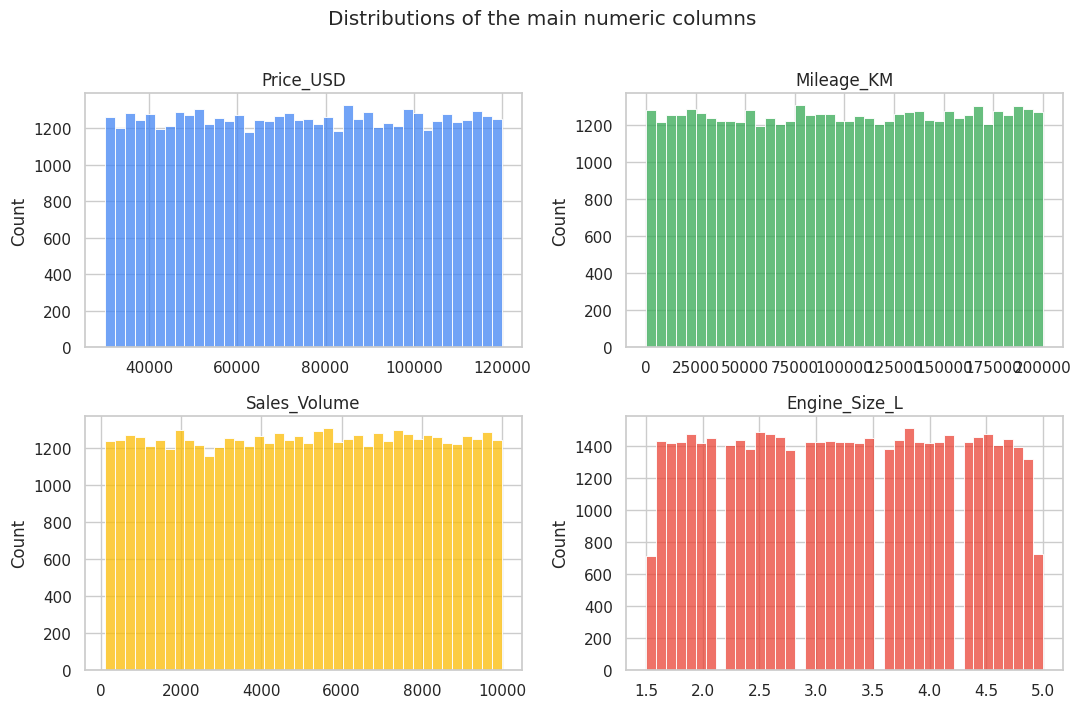

,column,min,max,KS p-value vs uniform
0,Price_USD,30000,119998,0.992
1,Mileage_KM,3,199996,0.259
2,Sales_Volume,100,9999,0.157


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col, color in zip(axes.ravel(),
                          ["Price_USD", "Mileage_KM", "Sales_Volume", "Engine_Size_L"],
                          ["#4285f4", "#34a853", "#fbbc04", "#ea4335"]):
    sns.histplot(df[col], bins=40, ax=ax, color=color)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distributions of the main numeric columns", y=1.01)
plt.tight_layout()
plt.savefig("images/distributions.png", dpi=150, bbox_inches="tight")
plt.show()

# Kolmogorov-Smirnov test against a uniform distribution (columns with a wide integer range)
rows = []
for col in ["Price_USD", "Mileage_KM", "Sales_Volume"]:
    x = df[col]
    scaled = (x - x.min()) / (x.max() - x.min())
    ks = stats.kstest(scaled, "uniform")
    rows.append({"column": col, "min": x.min(), "max": x.max(), "KS p-value vs uniform": round(ks.pvalue, 3)})
pd.DataFrame(rows)

### 2c. Implausible combinations

In [5]:
print("Engine size (L) by fuel type:")
print(df.groupby("Fuel_Type")["Engine_Size_L"].agg(["count", "min", "mean", "max"]).round(2))
print()
print("Share of rows by model and fuel type (%):")
print((pd.crosstab(df["Model"], df["Fuel_Type"], normalize="index") * 100).round(1))

Engine size (L) by fuel type:
           count  min  mean  max
Fuel_Type                       
Diesel     12263  1.5  3.25  5.0
Electric   12471  1.5  3.24  5.0
Hybrid     12716  1.5  3.25  5.0
Petrol     12550  1.5  3.25  5.0

Share of rows by model and fuel type (%):
Fuel_Type  Diesel  Electric  Hybrid  Petrol
Model                                      
3 Series     24.7      25.2    26.2    23.9
5 Series     24.6      24.7    24.9    25.8
7 Series     25.1      24.2    25.8    24.9
M3           24.2      24.9    26.2    24.7
M5           23.3      25.3    26.2    25.2
X1           24.6      25.9    25.0    24.6
X3           24.5      24.9    25.6    25.0
X5           24.8      24.7    24.5    26.0
X6           23.8      24.8    25.5    25.8
i3           26.0      24.6    24.5    24.9
i8           24.2      25.0    25.4    25.4


## 3. Do vehicle attributes explain sales?

### 3a. Correlations between numeric columns

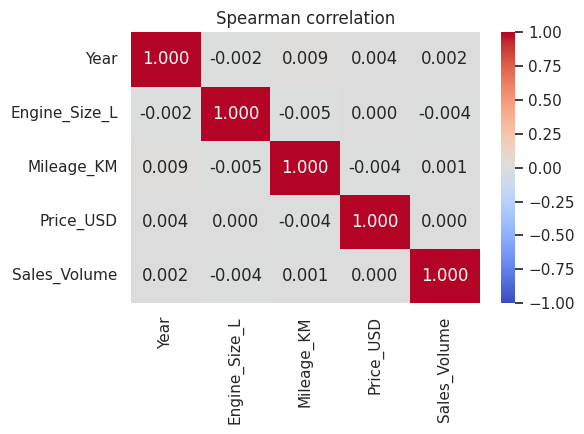

,feature,spearman_rho,p_value
0,Year,0.0017,0.7060
1,Engine_Size_L,-0.0039,0.3798
2,Mileage_KM,0.0014,0.7513
3,Price_USD,0.0000,0.9922


In [6]:
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150)
plt.show()

rows = []
for col in ["Year", "Engine_Size_L", "Mileage_KM", "Price_USD"]:
    rho, p = stats.spearmanr(df[col], df["Sales_Volume"])
    rows.append({"feature": col, "spearman_rho": round(rho, 4), "p_value": round(p, 4)})
pd.DataFrame(rows)

### 3b. Does average sales volume differ between groups? (Kruskal-Wallis)

In [7]:
df["Year_cat"] = df["Year"].astype(str)
rows = []
for col in cat_cols + ["Year_cat"]:
    groups = [g["Sales_Volume"].values for _, g in df.groupby(col)]
    H, p = stats.kruskal(*groups)
    k, n = len(groups), len(df)
    eps2 = max((H - k + 1) / (n - k), 0)   # effect size (epsilon squared)
    rows.append({"grouping": col, "groups": k, "H": round(H, 2),
                 "p_value": round(p, 4), "effect_size": round(eps2, 5)})
kw = pd.DataFrame(rows)
kw

,grouping,groups,H,p_value,effect_size
0,Model,11,5.31,0.8696,0
1,Region,6,4.35,0.5001,0
2,Color,6,4.98,0.4182,0
3,Fuel_Type,4,1.30,0.7291,0
4,Transmission,2,0.11,0.7379,0
5,Year_cat,15,9.31,0.8106,0


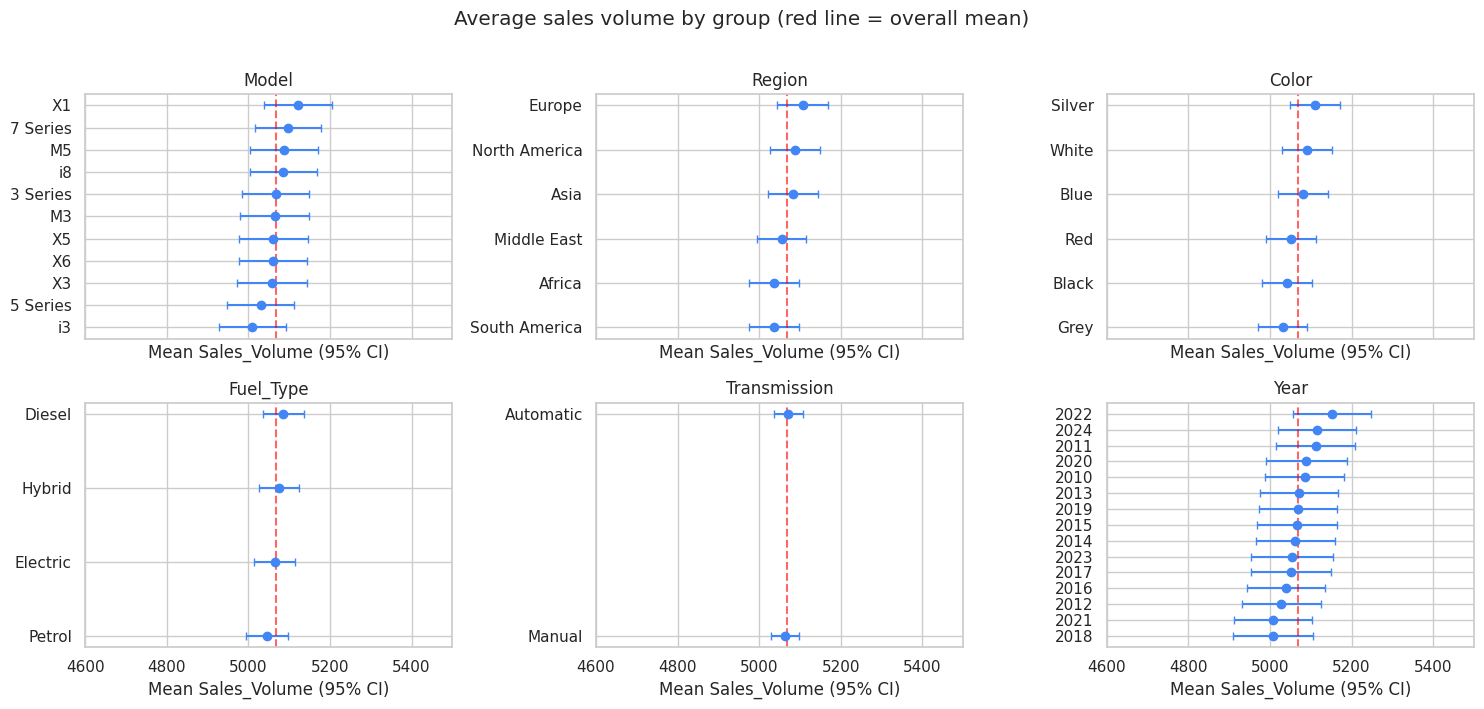

In [8]:
overall = df["Sales_Volume"].mean()
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, col in zip(axes.ravel(), cat_cols + ["Year_cat"]):
    g = df.groupby(col)["Sales_Volume"].agg(["mean", "sem"]).sort_values("mean")
    ax.errorbar(g["mean"], range(len(g)), xerr=1.96 * g["sem"], fmt="o", color="#4285f4", capsize=3)
    ax.axvline(overall, color="red", linestyle="--", alpha=0.6)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels(g.index)
    ax.set_title(col.replace("_cat", ""))
    ax.set_xlim(4600, 5500)
    ax.set_xlabel("Mean Sales_Volume (95% CI)")
plt.suptitle("Average sales volume by group (red line = overall mean)", y=1.01)
plt.tight_layout()
plt.savefig("images/group_means_ci.png", dpi=150, bbox_inches="tight")
plt.show()

### 3c. Is High vs Low related to any attribute? (chi-square)

In [9]:
rows = []
for col in cat_cols + ["Year_cat"]:
    table = pd.crosstab(df[col], df["Sales_Classification"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    share_high = (table["High"] / table.sum(axis=1)) * 100
    rows.append({"grouping": col, "chi2": round(chi2, 2), "p_value": round(p, 4),
                 "min_%_High": round(share_high.min(), 1), "max_%_High": round(share_high.max(), 1)})
pd.DataFrame(rows)

,grouping,chi2,p_value,min_%_High,max_%_High
0,Model,3.37,0.9714,29.5,30.9
1,Region,6.27,0.2812,29.9,31.3
2,Color,6.90,0.2281,29.9,31.1
3,Fuel_Type,0.22,0.9748,30.4,30.6
4,Transmission,0.13,0.7199,30.4,30.6
5,Year_cat,13.28,0.5045,29.4,32.3


## 4. Can a model predict High vs Low sales?

Features: model, year, region, color, fuel type, transmission, engine size, mileage, and price.
`Sales_Volume` is excluded because the classification is derived from it (see 2a).
A dummy model that always predicts the majority class is the benchmark; ROC-AUC of 0.5 means no better than chance.

In [10]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, RocCurveDisplay

y = (df["Sales_Classification"] == "High").astype(int)
X = pd.get_dummies(df[cat_cols + ["Year", "Engine_Size_L", "Mileage_KM", "Price_USD"]],
                   drop_first=True).astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Dummy (majority class)": DummyClassifier(strategy="prior"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fitted[name] = model
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "f1_high": f1_score(y_test, pred, zero_division=0),
                 "roc_auc": roc_auc_score(y_test, proba)})

print(f"Share of High in test set: {y_test.mean():.3f} (accuracy of always predicting Low: {1 - y_test.mean():.3f})")
results = pd.DataFrame(rows).set_index("model").round(3)
results

Share of High in test set: 0.305 (accuracy of always predicting Low: 0.695)


,accuracy,f1_high,roc_auc
model,,,
Dummy (majority class),0.695,0.0,0.500
Logistic Regression,0.695,0.0,0.490
Random Forest,0.695,0.0,0.494
Hist Gradient Boosting,0.695,0.0,0.493


In [11]:
# 5-fold cross-validated ROC-AUC for the two fastest models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name in ["Logistic Regression", "Hist Gradient Boosting"]:
    scores = cross_val_score(models[name], X, y, cv=cv, scoring="roc_auc")
    cv_rows.append({"model": name, "cv_auc_mean": scores.mean().round(3), "cv_auc_std": scores.std().round(3)})
pd.DataFrame(cv_rows).set_index("model")

,cv_auc_mean,cv_auc_std
model,,
Logistic Regression,0.499,0.007
Hist Gradient Boosting,0.499,0.005


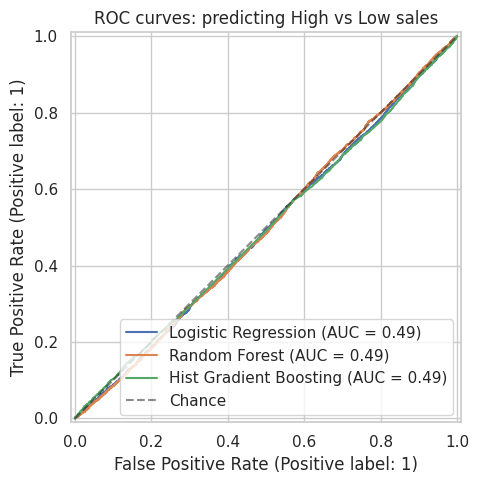

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, model in fitted.items():
    if name.startswith("Dummy"):
        continue
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance")
ax.set_title("ROC curves: predicting High vs Low sales")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/roc_no_signal.png", dpi=150)
plt.show()

### Target leakage demonstration

If `Sales_Volume` is included as a feature, the model looks perfect. That is not skill: the label is a rule applied to that column.

In [13]:
from sklearn.tree import DecisionTreeClassifier

stump = DecisionTreeClassifier(max_depth=1, random_state=42)
stump.fit(df[["Sales_Volume"]].loc[X_train.index], y_train)
proba = stump.predict_proba(df[["Sales_Volume"]].loc[X_test.index])[:, 1]

print("Single split learned by the tree: Sales_Volume <=", stump.tree_.threshold[0])
print("Test accuracy:", round(accuracy_score(y_test, (proba >= 0.5).astype(int)), 3))
print("Test ROC-AUC :", round(roc_auc_score(y_test, proba), 3))

Single split learned by the tree: Sales_Volume <= 6999.5
Test accuracy: 1.0
Test ROC-AUC : 1.0


## 5. Save the figures

In [14]:
import shutil
shutil.make_archive("images", "zip", "images")
from google.colab import files
files.download("images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>